# Análise exploratória dos dados (EDA)
Aqui olhamos para os dados para perceber o que temos, antes de criar modelos. Usamos gráficos e números simples para responder a perguntas como: quantos dados há? Como são? O que distingue o malware do resto?

**Passos:**
1. Conhecer os dados
2. Cada variável sozinha
3. Cada característica contra a classe
4. Várias características ao mesmo tempo
5. Correlação
6. Análises extra
7. Conclusões

**Sobre os dados:** 373 amostras, 531 características que valem 0 ou 1 (1 = o comportamento existe) e a coluna `Label` (malicious ou non-malicious).

Aqui só observamos. Escolhas que dependem do `Label` (como escolher características) fazem-se mais tarde, só com o treino.

O ficheiro `uci_malware_detection.csv` tem de estar na mesma pasta. Se faltarem bibliotecas: `!pip install -q seaborn scipy`.

## 1. Conhecer os dados
Abrimos o ficheiro e vemos o tamanho, os tipos, se faltam valores e se há linhas repetidas.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.feature_selection import mutual_info_classif
from pathlib import Path

filename = "uci_malware_detection.csv"

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

csv_path = next(
    (folder / filename
     for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / filename).is_file()),
    None
)

if csv_path is None:
    raise FileNotFoundError(
        f"Could not find {filename}. Place it in the notebook folder "
        "or a parent folder."
    )

df_raw = pd.read_csv(csv_path)
print('Dimensão original:', df_raw.shape)
print('Tipos:', df_raw.dtypes.value_counts().to_dict())
print('Valores em falta:', df_raw.isnull().sum().sum())
print('Linhas duplicadas:', df_raw.duplicated().sum())
df_raw.iloc[:5, :8]

Dimensão original: (373, 532)
Tipos: {dtype('int64'): 531, <StringDtype(storage='python', na_value=nan)>: 1}
Valores em falta: 0
Linhas duplicadas: 2


,Label,F_1,F_2,F_3,F_4,F_5,F_6,F_7
0,non-malicious,1,0,1,0,1,0,1
1,non-malicious,1,0,1,0,1,0,1
2,non-malicious,1,0,1,0,1,0,1
3,non-malicious,1,0,1,0,1,0,1
4,non-malicious,1,0,1,0,1,0,1


Para a análise, tiramos as linhas repetidas e as colunas com o mesmo valor em todas as linhas (não trazem informação).

In [2]:
df = df_raw.drop_duplicates().reset_index(drop=True)
feat_cols = [c for c in df.columns if c != 'Label']
constantes = [c for c in feat_cols if df[c].nunique() <= 1]
feat_cols = [c for c in feat_cols if c not in constantes]

X = df[feat_cols]
y = (df['Label'] == 'malicious').astype(int)     # 1 = malicious, 0 = non-malicious
nomes = {0: 'non-malicious', 1: 'malicious'}

print('Removidas:', len(df_raw) - len(df), 'linhas duplicadas e', len(constantes), 'colunas constantes')
print('Dimensão para o EDA: X =', X.shape)
print('Todas as features são 0/1:', X.isin([0, 1]).all().all())

Removidas: 2 linhas duplicadas e 28 colunas constantes
Dimensão para o EDA: X = (371, 503)
Todas as features são 0/1: True


## 2. Cada variável sozinha
Olhamos primeiro para o `Label` e depois para as características, uma de cada vez.

### 2.1 O que queremos prever (`Label`)
Contamos quantas amostras há de cada classe.

               amostras     %
Label                        
malicious           301  81.1
non-malicious        70  18.9


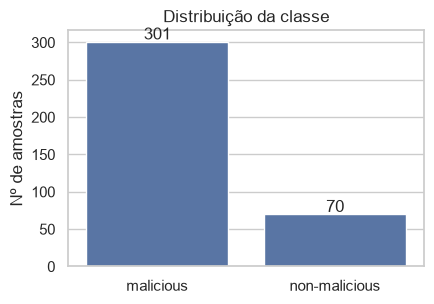

In [3]:
contagem = y.map(nomes).value_counts()
pct = y.map(nomes).value_counts(normalize=True).mul(100).round(1)
print(pd.DataFrame({'amostras': contagem, '%': pct}))

fig, ax = plt.subplots(figsize=(4.5, 3.2))
sns.barplot(x=contagem.index, y=contagem.values, ax=ax)
for i, v in enumerate(contagem.values):
    ax.text(i, v + 3, str(v), ha='center')
ax.set_title('Distribuição da classe'); ax.set_ylabel('Nº de amostras'); ax.set_xlabel('')
plt.tight_layout(); plt.show()

Cerca de 81% das amostras são `malicious`. Ou seja, os dois grupos não têm o mesmo tamanho. Isto é importante para escolher como avaliar os modelos.

### 2.2 Com que frequência aparece cada característica
Como cada característica vale 0 ou 1, a média diz-nos em que percentagem das amostras ela aparece.

count    503.000
mean       0.208
std        0.336
min        0.003
25%        0.016
50%        0.043
75%        0.112
max        0.997
dtype: float64


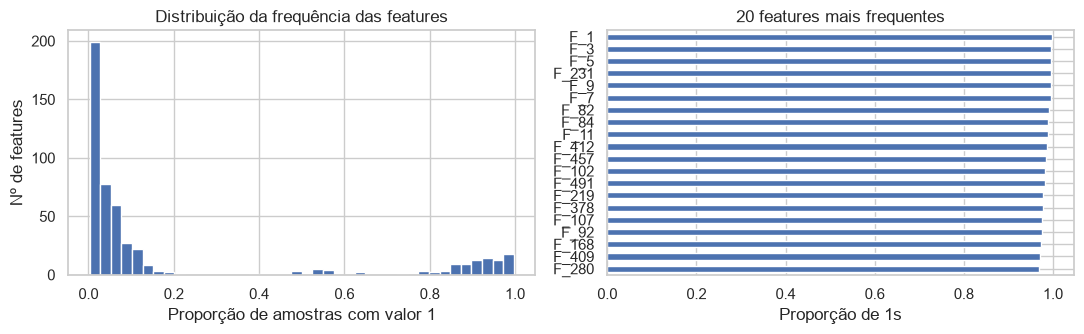

In [4]:
freq = X.mean().sort_values(ascending=False)
print(freq.describe().round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(freq, bins=40)
axes[0].set_title('Distribuição da frequência das features')
axes[0].set_xlabel('Proporção de amostras com valor 1'); axes[0].set_ylabel('Nº de features')

freq.head(20).sort_values().plot(kind='barh', ax=axes[1])
axes[1].set_title('20 features mais frequentes'); axes[1].set_xlabel('Proporção de 1s')
plt.tight_layout(); plt.show()

In [5]:
print('Features presentes em menos de 5% das amostras:', int((freq < 0.05).sum()), 'de', len(freq))
print('Features presentes em mais de 95% das amostras:', int((freq > 0.95).sum()))

Features presentes em menos de 5% das amostras: 268 de 503
Features presentes em mais de 95% das amostras: 31


A maior parte das características é **rara**: aparece em poucas amostras. Isto é normal neste tipo de dados.

### 2.3 Quantas características estão ativas em cada amostra
Contamos quantos 1 tem cada amostra.

count    371.0
mean     104.5
std       28.8
min        0.0
25%       96.0
50%       98.0
75%      101.0
max      253.0
dtype: float64


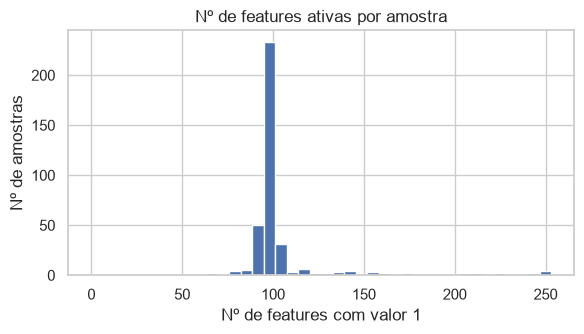

In [6]:
n_ativas = X.sum(axis=1)
print(n_ativas.describe().round(1))

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(n_ativas, bins=40)
ax.set_title('Nº de features ativas por amostra'); ax.set_xlabel('Nº de features com valor 1'); ax.set_ylabel('Nº de amostras')
plt.tight_layout(); plt.show()

### 2.4 Assimetria e curtose
São duas medidas do roadmap que descrevem a "forma" dos dados. Aqui só confirmam que a maior parte das características está quase sempre a 0, e umas poucas quase sempre a 1.

In [7]:
sk = X.skew(); ku = X.kurt()
print('Skewness: mediana =', round(sk.median(), 2), '| mín =', round(sk.min(), 2), '| máx =', round(sk.max(), 2))
print('Kurtosis: mediana =', round(ku.median(), 2))
print('Features com skewness > 1 (cauda à direita):', int((sk > 1).sum()), 'de', len(sk))

Skewness: mediana = 4.52 | mín = -19.26 | máx = 19.26
Kurtosis: mediana = 23.91
Features com skewness > 1 (cauda à direita): 400 de 503


## 3. Cada característica contra a classe
Vemos como cada característica se relaciona com malicious / non-malicious.

### 3.1 Número de características ativas por classe
Comparamos as duas classes.

               count   mean   std   min   25%    50%    75%    max
classe                                                            
malicious      301.0   97.2   6.4   0.0  96.0   98.0  100.0  104.0
non-malicious   70.0  135.8  55.4  20.0  96.0  119.0  163.2  253.0


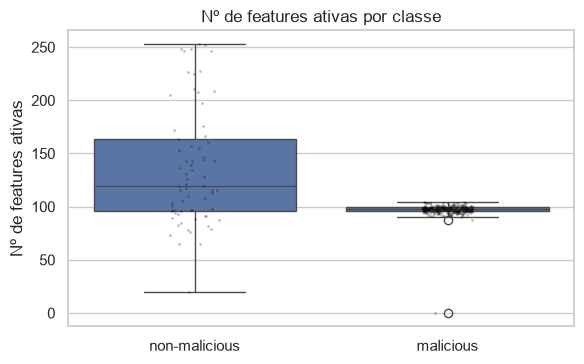

In [8]:
tmp = pd.DataFrame({'n_ativas': n_ativas, 'classe': y.map(nomes)})
print(tmp.groupby('classe')['n_ativas'].describe().round(1))

fig, ax = plt.subplots(figsize=(6, 3.8))
sns.boxplot(data=tmp, x='classe', y='n_ativas', ax=ax)
sns.stripplot(data=tmp, x='classe', y='n_ativas', color='black', alpha=0.25, size=2, ax=ax)
ax.set_title('Nº de features ativas por classe'); ax.set_xlabel(''); ax.set_ylabel('Nº de features ativas')
plt.tight_layout(); plt.show()

In [9]:
print('Amostras sem nenhuma feature ativa:')
print(df.loc[n_ativas == 0, 'Label'].value_counts())

Amostras sem nenhuma feature ativa:
Label
malicious    1
Name: count, dtype: int64


As amostras `malicious` têm sempre quase o mesmo número de características ativas (à volta de 97). As `non-malicious` variam muito e, em média, têm mais. Ou seja, o malware tem um "perfil" parecido entre si.

Há também uma amostra `malicious` sem nenhuma característica ativa, que vale a pena verificar à parte.

### 3.2 Características que mais distinguem as classes
Para cada característica, comparamos a percentagem de vezes que aparece em cada classe.

In [10]:
prop = X.groupby(y.map(nomes)).mean().T
prop['diferenca'] = (prop['malicious'] - prop['non-malicious'])
prop['abs_dif'] = prop['diferenca'].abs()
top = prop.sort_values('abs_dif', ascending=False)
print(top.head(10).round(3))
print()
print('Features com |diferença| > 0.5:', int((top['abs_dif'] > 0.5).sum()))
print('Features com |diferença| > 0.9:', int((top['abs_dif'] > 0.9).sum()))

Label  malicious  non-malicious  diferenca  abs_dif
F_20       0.970          0.000      0.970    0.970
F_19       0.000          0.914     -0.914    0.914
F_139      0.997          0.143      0.854    0.854
F_140      0.000          0.800     -0.800    0.800
F_66       0.000          0.800     -0.800    0.800
F_67       0.997          0.200      0.797    0.797
F_162      0.997          0.229      0.768    0.768
F_318      0.047          0.814     -0.768    0.768
F_111      0.000          0.743     -0.743    0.743
F_51       0.997          0.257      0.740    0.740

Features com |diferença| > 0.5: 45
Features com |diferença| > 0.9: 2


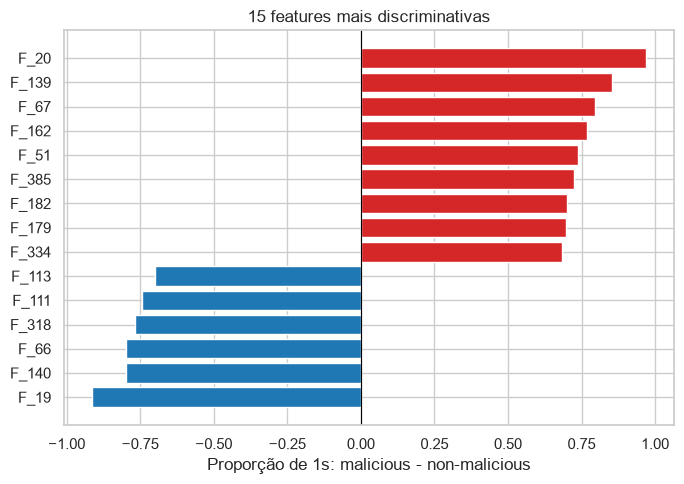

In [11]:
t = top.head(15).sort_values('diferenca')
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(t.index, t['diferenca'], color=np.where(t['diferenca'] > 0, 'tab:red', 'tab:blue'))
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Proporção de 1s: malicious - non-malicious')
ax.set_title('15 features mais discriminativas')
plt.tight_layout(); plt.show()

Várias características aparecem quase só numa das classes. É por isso que estes dados são fáceis de separar.

### 3.3 Teste estatístico (qui-quadrado)
Um teste que diz se a ligação entre uma característica e a classe é maior do que seria por acaso.

In [12]:
resultados = []
for c in feat_cols:
    tabela = pd.crosstab(X[c], y)
    if tabela.shape == (2, 2):
        chi2, p, _, _ = stats.chi2_contingency(tabela)
        resultados.append((c, chi2, p))
chi = pd.DataFrame(resultados, columns=['feature', 'chi2', 'p_value']).set_index('feature')
chi['sig_5pct'] = chi['p_value'] < 0.05
# com 500 testes, uma correção simples (Bonferroni) é mais prudente
chi['sig_bonferroni'] = chi['p_value'] < 0.05 / len(chi)

print('Features testadas:', len(chi))
print('Significativas a 5%:', int(chi['sig_5pct'].sum()))
print('Significativas com correção de Bonferroni:', int(chi['sig_bonferroni'].sum()))
chi.sort_values('chi2', ascending=False).head(8).round(4)

Features testadas: 503
Significativas a 5%: 481
Significativas com correção de Bonferroni: 373


,chi2,p_value,sig_5pct,sig_bonferroni
feature,,,,
F_19,326.1966,0.0,True,True
F_20,313.1428,0.0,True,True
F_139,295.1735,0.0,True,True
F_66,277.4010,0.0,True,True
F_140,277.4010,0.0,True,True
F_67,271.1110,0.0,True,True
F_162,259.3093,0.0,True,True
F_111,253.9215,0.0,True,True


Como fazemos centenas de testes, usamos uma correção (Bonferroni) para não aceitar resultados que apareceram só por sorte.

## 4. Várias características ao mesmo tempo
Vemos como as características se relacionam entre si e juntamos tudo num gráfico simples.

### 4.1 Mapa de relações entre as características mais importantes
As cores mostram se duas características tendem a aparecer juntas (vermelho) ou uma sem a outra (azul).

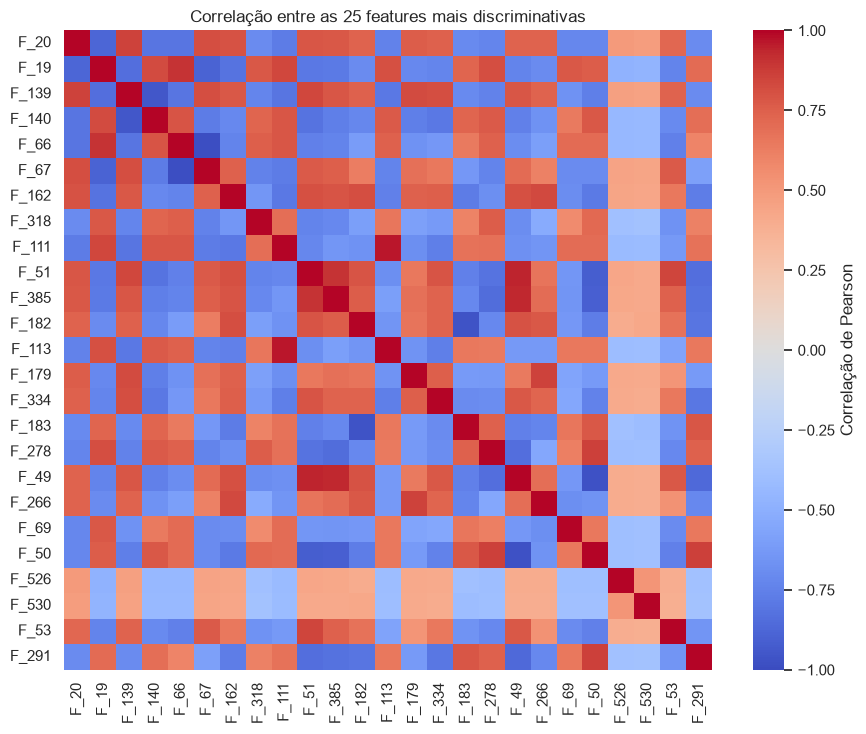

In [13]:
top_feats = top.head(25).index.tolist()
corr_top = X[top_feats].corr()

fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr_top, cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=ax,
            xticklabels=True, yticklabels=True, cbar_kws={'label': 'Correlação de Pearson'})
ax.set_title('Correlação entre as 25 features mais discriminativas')
plt.tight_layout(); plt.show()

### 4.2 PCA
Uma técnica que resume as mais de 500 características em apenas 2, para podermos desenhar as amostras num gráfico e ver se os dois grupos se separam.

Variância explicada pelas 5 primeiras componentes: [26.8 11.2  5.1  4.1  3.9]
Acumulada (10 componentes): 61.1 %


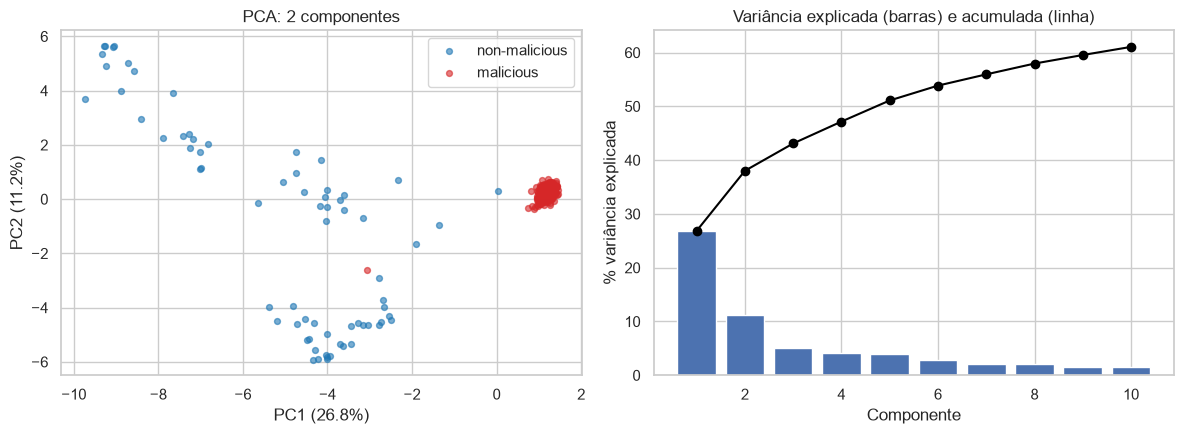

In [14]:
pca = PCA(n_components=10, random_state=RANDOM_STATE).fit(X)
var = pca.explained_variance_ratio_
print('Variância explicada pelas 5 primeiras componentes:', (var[:5] * 100).round(1))
print('Acumulada (10 componentes):', round(var.sum() * 100, 1), '%')

Z = pca.transform(X)[:, :2]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for cls, cor in [(0, 'tab:blue'), (1, 'tab:red')]:
    m = (y == cls).values
    axes[0].scatter(Z[m, 0], Z[m, 1], s=18, alpha=0.6, c=cor, label=nomes[cls])
axes[0].set_xlabel(f'PC1 ({var[0]*100:.1f}%)'); axes[0].set_ylabel(f'PC2 ({var[1]*100:.1f}%)')
axes[0].set_title('PCA: 2 componentes'); axes[0].legend()

axes[1].bar(range(1, 11), var * 100)
axes[1].plot(range(1, 11), np.cumsum(var) * 100, marker='o', color='black')
axes[1].set_xlabel('Componente'); axes[1].set_ylabel('% variância explicada')
axes[1].set_title('Variância explicada (barras) e acumulada (linha)')
plt.tight_layout(); plt.show()

**O que se vê:** o malware forma um grupo muito apertado, e as amostras `non-malicious` estão espalhadas, longe dele. Os dois grupos ficam bem separados.

## 5. Correlação (Pearson e Spearman)
Correlação mede se duas coisas andam juntas. Pearson e Spearman são duas maneiras de a calcular. Com valores só 0 e 1 dão o mesmo resultado, por isso a escolha não faz diferença aqui.

Diferença máxima Pearson vs Spearman: 0.0


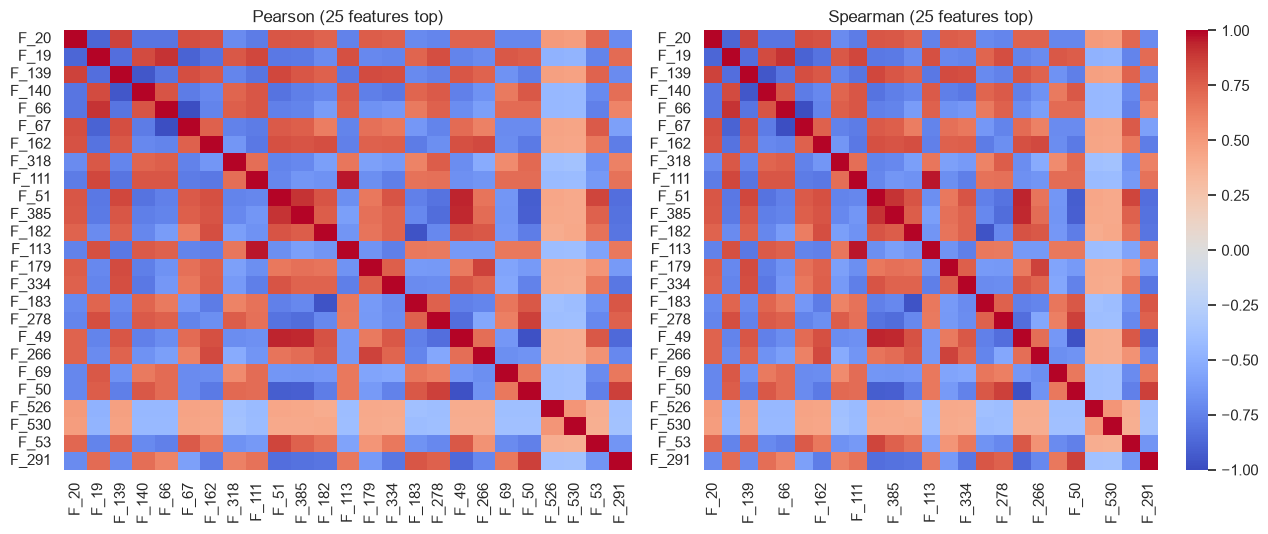

In [15]:
corr_p = X.corr(method='pearson')
corr_s = X.corr(method='spearman')

mask = np.triu(np.ones(corr_p.shape, dtype=bool), k=1)
dif = (corr_p - corr_s).abs().where(mask)
print('Diferença máxima Pearson vs Spearman:', round(np.nanmax(dif.values), 4))

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
sns.heatmap(corr_p.loc[top_feats, top_feats], cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=axes[0], cbar=False)
axes[0].set_title('Pearson (25 features top)')
sns.heatmap(corr_s.loc[top_feats, top_feats], cmap='coolwarm', center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Spearman (25 features top)')
plt.tight_layout(); plt.show()

### 5.1 Relação de cada característica com a classe
Vemos quais as características mais ligadas ao `Label`.

In [16]:
r_p = X.apply(lambda c: stats.pearsonr(c, y)[0])
r_s = X.apply(lambda c: stats.spearmanr(c, y)[0])
alvo = pd.DataFrame({'pearson': r_p, 'spearman': r_s})
alvo['abs'] = alvo['pearson'].abs()
print(alvo.sort_values('abs', ascending=False).head(10).round(3).drop(columns='abs'))
print()
print('Features com |r| > 0.5 com o alvo:', int((alvo['abs'] > 0.5).sum()))

       pearson  spearman
F_19    -0.947    -0.947
F_20     0.927     0.927
F_139    0.901     0.901
F_140   -0.874    -0.874
F_66    -0.874    -0.874
F_67     0.864     0.864
F_162    0.846     0.846
F_111   -0.837    -0.837
F_51     0.827     0.827
F_385    0.817     0.817

Features com |r| > 0.5 com o alvo: 121


### 5.2 Características repetidas
Se duas características dão a mesma informação, uma delas é desnecessária.

In [17]:
upper = corr_p.where(mask)
pares = upper.stack()
print('Pares com |r| > 0.95:', int((pares.abs() > 0.95).sum()))
print('Pares com |r| = 1 (colunas equivalentes):', int((pares.abs() > 0.9999).sum()))

# Grupos de colunas idênticas
grupos = X.T.groupby(list(X.index)).apply(lambda g: list(g.index))
grupos = [g for g in grupos if len(g) > 1]
print('Grupos de colunas idênticas:', len(grupos), '| colunas redundantes:', sum(len(g) - 1 for g in grupos))
print('Exemplos:', grupos[:3])

Pares com |r| > 0.95: 441
Pares com |r| = 1 (colunas equivalentes): 404
Grupos de colunas idênticas: 34 | colunas redundantes: 91
Exemplos: [['F_17', 'F_63', 'F_81', 'F_83', 'F_85', 'F_109', 'F_115', 'F_211', 'F_285', 'F_295', 'F_299', 'F_311', 'F_315', 'F_317', 'F_319', 'F_325', 'F_327', 'F_345', 'F_363', 'F_365', 'F_371', 'F_397', 'F_439'], ['F_87', 'F_381'], ['F_221', 'F_223', 'F_335', 'F_351', 'F_355']]


Muitas características são cópias umas das outras (ou o oposto exato). Podemos tirar as repetidas sem perder informação, e é o que fazemos mais à frente.

## 6. Análises extra

### 6.1 Informação mútua
Outra forma de medir quanto uma característica ajuda a adivinhar a classe (funciona mesmo quando a relação não é simples).

F_20     0.409
F_19     0.405
F_139    0.351
F_66     0.330
F_140    0.330
F_67     0.316
F_162    0.300
F_111    0.298
F_51     0.284
F_385    0.277
dtype: float64
Features com informação mútua > 0.1: 120


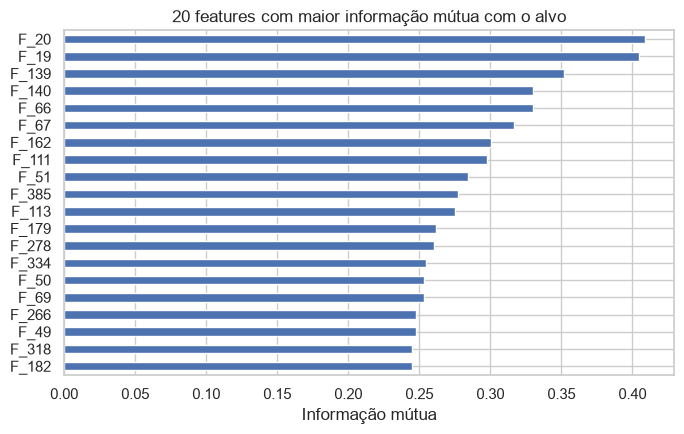

In [18]:
mi = pd.Series(mutual_info_classif(X, y, discrete_features=True, random_state=RANDOM_STATE), index=feat_cols)
mi = mi.sort_values(ascending=False)
print(mi.head(10).round(3))
print('Features com informação mútua > 0.1:', int((mi > 0.1).sum()))

fig, ax = plt.subplots(figsize=(7, 4.5))
mi.head(20).sort_values().plot(kind='barh', ax=ax)
ax.set_title('20 features com maior informação mútua com o alvo'); ax.set_xlabel('Informação mútua')
plt.tight_layout(); plt.show()

### 6.2 t-SNE
Outra forma de desenhar os dados em 2 dimensões, que pode mostrar grupos que o PCA não mostra.

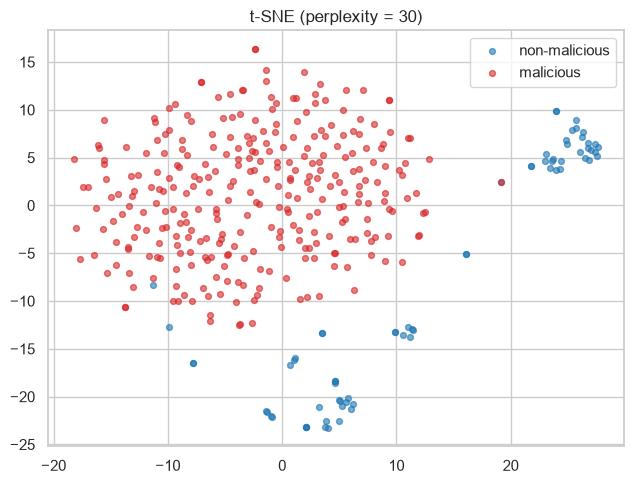

In [19]:
tsne = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE, init='pca')
T = tsne.fit_transform(X)

fig, ax = plt.subplots(figsize=(6.5, 5))
for cls, cor in [(0, 'tab:blue'), (1, 'tab:red')]:
    m = (y == cls).values
    ax.scatter(T[m, 0], T[m, 1], s=18, alpha=0.6, c=cor, label=nomes[cls])
ax.set_title('t-SNE (perplexity = 30)'); ax.legend()
plt.tight_layout(); plt.show()

### 6.3 Quão parecidas são as amostras
Medimos a percentagem de características em que duas amostras são diferentes. Quanto mais pequeno o valor, mais parecidas são.

In [20]:
from scipy.spatial.distance import pdist, squareform
D = squareform(pdist(X.values, metric='hamming'))
iu = np.triu_indices_from(D, k=1)

yv = y.values
mm = (yv[:, None] == 1) & (yv[None, :] == 1)
nn = (yv[:, None] == 0) & (yv[None, :] == 0)
mn = (yv[:, None] != yv[None, :])
print('Distância média (Hamming) entre malicious :', round(D[mm & np.triu(np.ones_like(D, dtype=bool), 1)].mean(), 4))
print('Distância média (Hamming) entre non-malicious:', round(D[nn & np.triu(np.ones_like(D, dtype=bool), 1)].mean(), 4))
print('Distância média (Hamming) entre classes     :', round(D[mn & np.triu(np.ones_like(D, dtype=bool), 1)].mean(), 4))

Distância média (Hamming) entre malicious : 0.0356
Distância média (Hamming) entre non-malicious: 0.2701
Distância média (Hamming) entre classes     : 0.2316


**Resultado:** as amostras `malicious` são muito parecidas entre si (diferem em cerca de 4% das características). As `non-malicious` são mais diferentes umas das outras (cerca de 27%).

Isto pode ser um problema: no treino e no teste podem existir amostras quase iguais, o que faz o modelo parecer melhor do que realmente é. Por isso, resultados muito altos devem ser vistos com cuidado.

## 7. Conclusões

| O que vimos | O que significa |
|---|---|
| Cerca de 81% são `malicious` | Não usar só a percentagem de acertos; olhar para a classe mais pequena |
| Muitas características raras | É normal, não é preciso tratar |
| Muitas características repetidas | Podemos tirar as repetidas |
| Classes bem separadas | Esperamos bons resultados, mas devemos desconfiar de resultados perfeitos |
| Malware muito parecido entre si | Os resultados podem estar inflacionados |
| Poucas amostras da classe pequena | Usar validação cruzada |

**Ideia:** o número de características ativas em cada amostra distingue bem as classes. Podemos usá-lo como característica nova.